# 02 - NOAA Storm Events data quality

What values we have, what is null or missing, and anything that looks wrong.
Data: `storms/storm_events_YYYY.parquet` (one row per NOAA event, study-area states) and
`storms/storm_event_counties.parquet` (events mapped to counties).

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.data import load_storm_events, load_storm_counties, load_zone_county, load_census

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

ev = pd.concat([load_storm_events(y) for y in C.YEARS], ignore_index=True)
ev["state_abbr"] = ev["state_fips"].map(C.STATES)
print(ev.shape)

(94350, 58)


## 1. Rows per year and state

In [2]:
ev.pivot_table(index="year", columns="state_abbr", values="event_id", aggfunc="count", margins=True)

state_abbr,AL,FL,GA,NC,SC,TN,All
year,,,,,,,
2014,890,1121,1228,1557,782,1143,6721
2015,892,1200,1355,1384,1317,1181,7329
2016,976,1065,1664,1656,1113,1592,8066
2017,1301,1155,1679,1224,912,1404,7675
2018,1027,985,1257,1846,929,1419,7463
2019,1118,939,1158,1447,827,1158,6647
2020,1353,1274,1535,1691,869,1133,7855
2021,1186,920,847,904,465,1285,5607
2022,1030,1242,1106,1586,1146,1599,7709


## 2. Every column: type, % null, number of distinct values, an example

In [3]:
cols = pd.DataFrame({
    "dtype": ev.dtypes.astype(str),
    "pct_null": (100 * ev.isna().mean()).round(1),
    "distinct": ev.nunique(),
    "example": ev.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
cols.sort_values("pct_null")

,dtype,pct_null,distinct,example
begin_yearmonth,int64,0.0,144,201401
begin_day,int64,0.0,31,9
begin_time,int64,0.0,1440,1819
end_yearmonth,int64,0.0,144,201401
end_day,int64,0.0,31,9
end_time,int64,0.0,1440,1820
episode_id,int64,0.0,14273,80618
event_id,int64,0.0,94350,482601
state,str,0.0,6,FLORIDA
state_fips,str,0.0,6,12


Many columns only apply to some event types (e.g. `tor_f_scale` is tornado only), so a high
null % is not always a problem. This shows % null for the useful columns, by event type.

In [4]:
key = ["magnitude", "magnitude_type", "tor_f_scale", "category", "flood_cause",
       "damage_property", "damage_crops", "begin_lat", "end_lat", "event_narrative"]
by_type = ev.groupby("event_type")[key].agg(lambda s: round(100 * s.isna().mean()))
by_type.insert(0, "events", ev["event_type"].value_counts())
by_type.sort_values("events", ascending=False)

,events,magnitude,magnitude_type,tor_f_scale,category,flood_cause,damage_property,damage_crops,begin_lat,end_lat,event_narrative
event_type,,,,,,,,,,,
Thunderstorm Wind,45237,0,0,100,100,100,23,29,0,0,0
Hail,8958,0,100,100,100,100,40,36,0,0,22
Flash Flood,7446,100,100,100,100,0,0,0,0,0,0
Drought,3696,100,100,100,100,100,34,37,100,100,51
Winter Weather,3680,100,100,100,100,100,19,16,100,100,33
Tornado,3405,100,100,0,100,100,25,29,0,0,0
Flood,2648,100,100,100,100,0,0,0,0,0,0
Winter Storm,2498,100,100,100,100,100,27,20,100,100,15
Tropical Storm,2248,100,100,100,100,100,26,30,100,100,16


## 3. Event types

In [5]:
ev.pivot_table(index="event_type", columns="year", values="event_id", aggfunc="count", fill_value=0) \
    .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False)

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,total
event_type,,,,,,,,,,,,,
Thunderstorm Wind,3024,3631,3593,3588,3288,3691,3996,2298,3538,6134,3737,4719,45237
Hail,820,716,749,960,594,538,544,655,757,953,662,1010,8958
Flash Flood,390,588,490,435,547,367,922,802,410,588,1155,752,7446
Drought,42,0,1145,312,136,322,13,4,220,484,440,578,3696
Winter Weather,510,451,346,302,537,194,256,309,365,28,177,205,3680
Tornado,204,133,189,402,215,280,388,321,308,324,379,262,3405
Flood,160,312,204,205,292,193,398,169,183,153,228,151,2648
Winter Storm,460,435,169,171,284,16,60,145,272,39,36,411,2498
Tropical Storm,17,12,292,270,310,78,308,123,229,148,455,6,2248


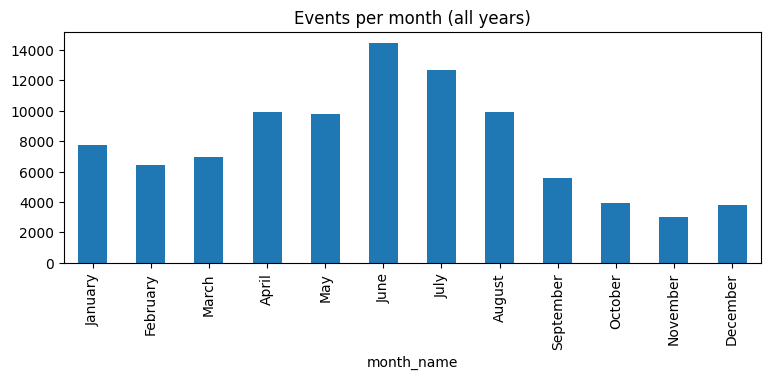

In [6]:
ev.groupby("month_name").size().reindex(
    ["January", "February", "March", "April", "May", "June", "July",
     "August", "September", "October", "November", "December"]).plot.bar(figsize=(9, 3))
plt.title("Events per month (all years)")
plt.show()

## 4. Categorical values

In [7]:
for col in ["cz_type", "magnitude_type", "tor_f_scale", "flood_cause", "category",
            "cz_timezone", "data_source"]:
    print(f"--- {col}")
    print(ev[col].value_counts(dropna=False).to_string(), "\n")

--- cz_type
cz_type
C    71513
Z    22837 

--- magnitude_type
magnitude_type
NaN    46813
EG     45184
MG      2330
MS        13
ES        10 

--- tor_f_scale
tor_f_scale
NaN    90945
EF0     1558
EF1     1358
EF2      334
EF3       85
EFU       62
EF4        8 

--- flood_cause
flood_cause
NaN                             84222
Heavy Rain                       9069
Heavy Rain / Tropical System     1023
Dam / Levee Break                  29
Heavy Rain / Snow Melt              4
Planned Dam Release                 2
Ice Jam                             1 

--- category
category
NaN    94126
1.0      154
2.0       38
3.0       18
4.0       13
5.0        1 

--- cz_timezone
cz_timezone
EST-5    62740
CST-6    31559
EDT-4       51 

--- data_source
data_source
CSV    94350 



In [8]:
ev["source"].value_counts(dropna=False).head(15)

source
Emergency Manager         20430
911 Call Center           12587
Public                    10889
Law Enforcement            5731
Trained Spotter            4952
Broadcast Media            4747
NWS Storm Survey           3958
Social Media               3826
Drought Monitor            3594
Mesonet                    2627
CoCoRaHS                   2576
State Official             2396
ASOS                       2255
AWOS                       2159
Fire Department/Rescue     1461
Name: count, dtype: int64

## 5. Magnitude

`magnitude` means different things by type: wind speed in knots for wind events
(EG = estimated gust, MG = measured gust, ES/MS = sustained) and hail size in inches for Hail.

In [9]:
ev.groupby(["event_type", "magnitude_type"], dropna=False)["magnitude"] \
    .describe().dropna(subset=["count"]).query("count > 0").round(2)

count   mean   std    min    25%   50%    75%     max
event_type        magnitude_type                                                         
Hail              NaN              8958.0   1.13  0.42   0.25   0.88   1.0   1.25    5.38
High Wind         EG                504.0  52.19  4.57  35.00  50.00  50.0  52.25   87.00
                  ES                  3.0  46.67  6.35  43.00  43.00  43.0  48.50   54.00
                  MG                430.0  58.15  8.13  41.00  52.00  56.0  62.00   91.00
                  MS                 10.0  42.90  5.30  35.00  42.00  42.5  43.00   56.00
Strong Wind       EG               1103.0  40.40  4.39  22.00  39.00  40.0  44.00   49.00
                  ES                  4.0  31.25  2.50  30.00  30.00  30.0  31.25   35.00
                  MG                243.0  41.25  4.39  26.00  38.50  41.0  45.00   49.00
                  MS                  3.0  32.00  3.46  30.00  30.00  30.0  33.00   36.00
Thunderstorm Wind EG              43577.0  51.10  5.14   1.00  50.00  50.0  52.00  100.00
                  ES                  3.0  66.67  9.81  61.00  61.00  61.0  69.50   78.00
                  MG               1657.0  54.06  6.51  28.00  51.00  53.0  56.00   92.00

## 6. Damage, deaths, injuries

NOAA writes damage as text like `25.00K`; `damage_property_usd` is our parsed number.
Check for text that did not parse, and how often damage is blank vs zero.

In [10]:
for col in ["damage_property", "damage_crops"]:
    usd = col + "_usd"
    bad = ev[ev[col].notna() & ev[usd].isna()][col]
    print(f"{col}: blank {ev[col].isna().mean():.1%}, zero {(ev[usd] == 0).mean():.1%}, "
          f"> 0 {(ev[usd] > 0).mean():.1%}, did not parse {len(bad)} {bad.unique()[:10]}")

damage_property: blank 21.9%, zero 45.7%, > 0 32.5%, did not parse 0 <ArrowStringArray>
[]
Length: 0, dtype: str
damage_crops: blank 24.3%, zero 74.6%, > 0 1.1%, did not parse 0 <ArrowStringArray>
[]
Length: 0, dtype: str


In [11]:
ev[["damage_property_usd", "damage_crops_usd", "injuries_direct", "injuries_indirect",
    "deaths_direct", "deaths_indirect"]].describe().round(0)

,damage_property_usd,damage_crops_usd,injuries_direct,injuries_indirect,deaths_direct,deaths_indirect
count,7.372200e+04,71434.0,94350.0,94350.0,94350.0,94350.0
mean,7.581440e+05,124090.0,0.0,0.0,0.0,0.0
std,4.050992e+07,4821141.0,1.0,0.0,0.0,0.0
min,0.000000e+00,0.0,0.0,0.0,0.0,0.0
25%,0.000000e+00,0.0,0.0,0.0,0.0,0.0
50%,0.000000e+00,0.0,0.0,0.0,0.0,0.0
75%,2.000000e+03,0.0,0.0,0.0,0.0,0.0
max,7.000000e+09,500000000.0,170.0,30.0,60.0,21.0


In [12]:
ev.nlargest(10, "damage_property_usd")[
    ["year", "state", "event_type", "cz_name", "damage_property", "damage_property_usd"]]

,year,state,event_type,cz_name,damage_property,damage_property_usd
62525,2022,FLORIDA,Hurricane (Typhoon),COASTAL LEE,7.00B,7.000000e+09
37034,2018,FLORIDA,Hurricane (Typhoon),COASTAL BAY,6.00B,6.000000e+09
62598,2022,FLORIDA,Hurricane (Typhoon),COASTAL CHARLOTTE,3.00B,3.000000e+09
64804,2022,FLORIDA,Hurricane (Typhoon),COASTAL COLLIER COUNTY,2.20B,2.200000e+09
19210,2016,FLORIDA,Tropical Storm,ST. JOHNS,2.00B,2.000000e+09
62526,2022,FLORIDA,Hurricane (Typhoon),COASTAL SARASOTA,2.00B,2.000000e+09
44841,2020,TENNESSEE,Tornado,DAVIDSON,1.09B,1.090000e+09
37124,2018,NORTH CAROLINA,Hurricane (Typhoon),INLAND NEW HANOVER,1.00B,1.000000e+09
62669,2022,FLORIDA,Hurricane (Typhoon),COASTAL MANATEE,1.00B,1.000000e+09
83188,2024,FLORIDA,Hurricane (Typhoon),INLAND TAYLOR,1.00B,1.000000e+09


## 7. Times

Check for missing times, end before begin, and how long events last.

In [13]:
print("null begin_utc:", ev["begin_utc"].isna().sum(), "| null end_utc:", ev["end_utc"].isna().sum())
ev["hours"] = (ev["end_utc"] - ev["begin_utc"]).dt.total_seconds() / 3600
print("end before begin:", (ev["hours"] < 0).sum())
print("zero length (begin == end):", (ev["hours"] == 0).sum())
print("timezones -> UTC offset check:")
print(ev.assign(offset=(ev["begin_local"] - ev["begin_utc"]).dt.total_seconds() / 3600)
      .groupby("cz_timezone")["offset"].unique())

null begin_utc: 0 | null end_utc: 0
end before begin: 0
zero length (begin == end): 38124
timezones -> UTC offset check:
cz_timezone
CST-6    [-6.0]
EDT-4    [-4.0]
EST-5    [-5.0]
Name: offset, dtype: object


In [14]:
ev.groupby("event_type")["hours"].describe(percentiles=[.5, .9]).round(1) \
    .sort_values("count", ascending=False)

,count,mean,std,min,50%,90%,max
event_type,,,,,,,
Thunderstorm Wind,45237.0,0.1,2.2,0.0,0.0,0.1,384.1
Hail,8958.0,0.0,0.1,0.0,0.0,0.1,1.4
Flash Flood,7446.0,3.3,5.6,0.0,2.0,6.0,244.9
Drought,3696.0,567.1,225.7,17.0,720.0,744.0,744.0
Winter Weather,3680.0,11.7,9.3,0.0,9.0,21.0,155.0
Tornado,3405.0,0.1,0.1,0.0,0.1,0.2,0.9
Flood,2648.0,12.1,33.4,0.0,3.1,25.0,552.0
Winter Storm,2498.0,16.2,9.7,0.0,13.3,29.0,174.5
Tropical Storm,2248.0,12.8,15.6,0.0,9.0,28.8,221.0


## 8. IDs and duplicates

In [15]:
print("duplicate event_id:", ev["event_id"].duplicated().sum())
print("fully duplicated rows:", ev.drop(columns=["hours"]).duplicated().sum())
size = ev.groupby("episode_id").size()
print(f"{len(size):,} episodes; events per episode:")
size.describe(percentiles=[.5, .9, .99]).round(1)

duplicate event_id: 0


fully duplicated rows: 0
14,273 episodes; events per episode:


count    14273.0
mean         6.6
std         11.5
min          1.0
50%          3.0
90%         16.0
99%         54.0
max        412.0
dtype: float64

## 9. Locations

Lat/lon only exist for some event types. Points outside the study area are suspicious.

In [16]:
box = ev["begin_lat"].between(24, 37.5) & ev["begin_lon"].between(-91, -75)
print("has begin_lat:", ev["begin_lat"].notna().mean().round(3))
print("outside the Southeast box:", (ev["begin_lat"].notna() & ~box).sum())
ev[ev["begin_lat"].notna() & ~box][["year", "state", "event_type", "cz_name", "begin_lat", "begin_lon"]].head(10)

has begin_lat: 0.757
outside the Southeast box: 0


,year,state,event_type,cz_name,begin_lat,begin_lon


## 10. Mapping events to counties

County events (`cz_type == "C"`) map directly. Zone events (`"Z"`) go through the NWS
zone -> county lookup, which is today's zones, so some older zone codes do not match.

In [17]:
zc = load_zone_county()
zones = ev[ev["cz_type"] == "Z"].merge(
    zc[["state", "zone"]].drop_duplicates(), left_on=["state_abbr", "cz_fips"],
    right_on=["state", "zone"], how="left", indicator=True, suffixes=("", "_zc"))
zones["matched"] = zones["_merge"] == "both"
print(f"zone events: {len(zones):,}, unmatched: {(~zones['matched']).mean():.1%}")
zones.groupby("event_type")["matched"].agg(events="size", unmatched=lambda s: (~s).sum()) \
    .query("unmatched > 0").sort_values("unmatched", ascending=False)

zone events: 22,837, unmatched: 6.6%


,events,unmatched
event_type,,
Coastal Flood,771,358
Tropical Storm,2246,227
Rip Current,511,149
Strong Wind,1353,142
Winter Weather,3680,100
Winter Storm,2379,88
High Wind,947,79
Drought,3696,63
Storm Surge/Tide,233,51


In [18]:
zones[~zones["matched"]].groupby(["state_abbr", "cz_fips", "cz_name"]).size() \
    .sort_values(ascending=False).head(15)

state_abbr  cz_fips  cz_name             
SC          050      CHARLESTON              369
GA          119      COASTAL CHATHAM         109
SC          048      BEAUFORT                 74
            049      SOUTHERN COLLETON        56
NC          103      EASTERN DARE             43
FL          107      NORTH WALTON             38
            133      COASTAL ST. JOHNS        36
            047      BREVARD                  35
SC          003      GREENVILLE MOUNTAINS     34
            047      JASPER                   34
            001      OCONEE MOUNTAINS         33
            002      PICKENS MOUNTAINS        33
            006      GREATER GREENVILLE       30
FL          026      LIBERTY                  28
SC          004      GREATER OCONEE           27
dtype: int64

Check the final event -> county table.

In [19]:
sc = load_storm_counties(columns=["event_id", "fips_code", "mapped_from", "event_type"])
census_fips = set(load_census()["fips_code"])
print("rows:", len(sc), "| mapped_from:", sc["mapped_from"].value_counts().to_dict())
print("events lost in mapping:", len(ev) - sc["event_id"].nunique())
print("FIPS not in the census county list:", sorted(set(sc["fips_code"]) - census_fips))

rows: 92852 | mapped_from: {'county': 71513, 'zone': 21339}
events lost in mapping: 1498


FIPS not in the census county list: ['13002', '13004', '13006', '13008', '13012', '13014', '13016', '13020', '13022', '13024', '13030', '13032', '13034', '13036', '13038', '13041', '13042', '13044', '13046', '13048', '13050', '13052', '13054', '13056', '13058', '13060', '13062', '13066', '13068', '13070', '13072', '13074', '13076', '13078', '13080', '13082', '13084', '13086', '13090', '13092', '13094', '13096', '13098', '13102', '13104', '13106', '13108', '13110', '13112']


## 11. Summary

**Clean**
- 94,350 events, 2014-2025, all six states every year; no duplicate events.
- No missing times, no end-before-begin, UTC conversion matches each timezone; damage text all parsed.
- Every lat/lon falls inside the Southeast.

**What the nulls mean.** Most nulls are "does not apply", not missing data:
- `magnitude` is only filled for wind (knots) and hail (inches). Floods, tornadoes, hurricanes and
  winter storms have no magnitude; tornadoes use `tor_f_scale`, hurricanes rarely fill `category`.
- Damage is blank for 22% of events and $0 for 46%, so "no damage reported" and "$0" are hard to tell apart.
- Lat/lon exists only for point events (wind, hail, tornado, flood), not zone events.

**Problems to handle**
1. **Event types that don't cause outages**: Drought, Heat, Rip Current, Frost/Freeze, Fog and similar.
   Drought events last up to 744 h (a whole month). Drop them from the join.
2. **6.6% of zone events have no county match** (1,498 events lost), led by Coastal Flood and
   **Tropical Storm (227)**. Most are SC/GA coastal zones like Charleston and Coastal Chatham whose codes changed.
3. **59 Georgia Winter Storm rows have bad FIPS codes**: NOAA marked them as county events, but the
   numbers are zone codes, so they produce counties that don't exist (13002, 13004, ...).
4. **Wind speed is mostly estimated** (EG: 45k events) and often a round 50 knots; measured gusts (MG) are only 2k.
5. 2023 has many more Thunderstorm Wind events (6,134 vs about 3,600 most years); check before reading it as a trend.